In [6]:
from sklearn.datasets import fetch_california_housing

dados = fetch_california_housing(as_frame=True)

df = dados.frame

In [7]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [8]:
X = df.drop("MedHouseVal", axis=1)

y = df["MedHouseVal"]

In [9]:
print(X.head())
print(y.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64


In [10]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [11]:
print("Dados para treino:", X_treino.shape)
print("Dados para teste:", X_teste.shape)

Dados para treino: (16512, 8)
Dados para teste: (4128, 8)


In [12]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()

modelo.fit(X_treino, y_treino)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 0.45, 0.01,-0.12,...,-0. ,-0.42,-0.43]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-37.02
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [13]:
previsoes = modelo.predict(X_teste)

print(previsoes[:5])

[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]


In [14]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_teste, previsoes)
r2 = r2_score(y_teste, previsoes)

print(f"Erro médio absoluto: {mae:.2f}")
print(f"R²: {r2:.2f}")

Erro médio absoluto: 0.53
R²: 0.58


In [15]:
print(f"Erro médio aproximado: US$ {mae * 100000:,.0f}")

Erro médio aproximado: US$ 53,320


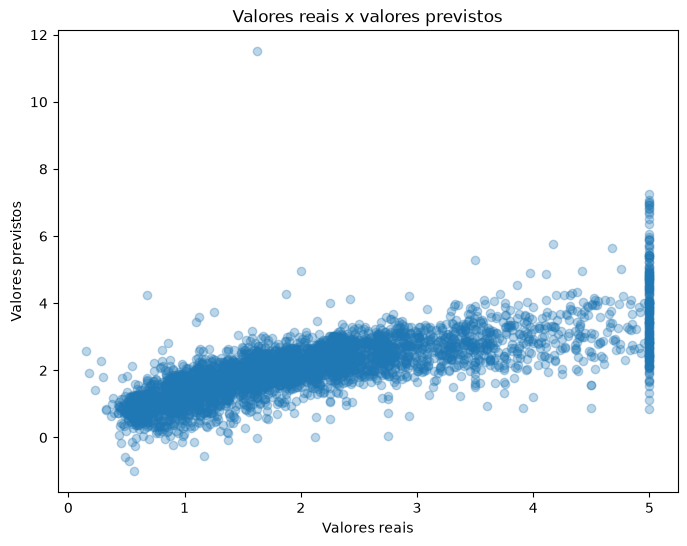

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_teste, previsoes, alpha=0.3)

plt.xlabel("Valores reais")
plt.ylabel("Valores previstos")
plt.title("Valores reais x valores previstos")

plt.show()

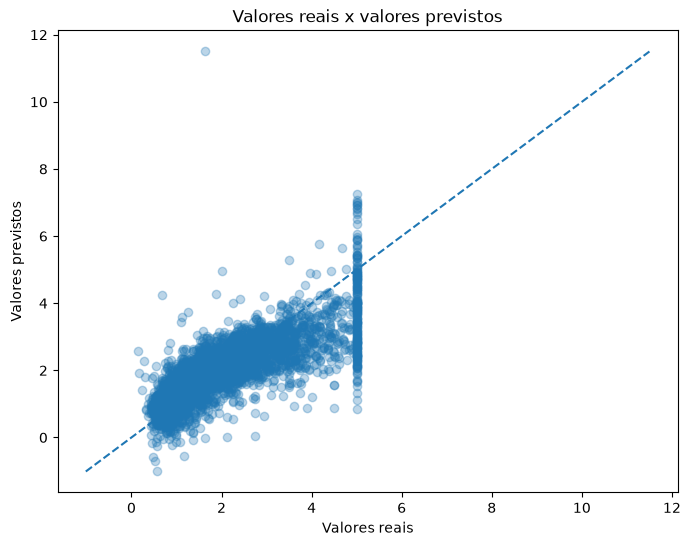

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_teste, previsoes, alpha=0.3)

limite_min = min(y_teste.min(), previsoes.min())
limite_max = max(y_teste.max(), previsoes.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--"
)

plt.xlabel("Valores reais")
plt.ylabel("Valores previstos")
plt.title("Valores reais x valores previstos")
plt.show()

In [18]:
from sklearn.ensemble import RandomForestRegressor

modelo_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

modelo_rf.fit(X_treino, y_treino)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [19]:
previsoes_rf = modelo_rf.predict(X_teste)

mae_rf = mean_absolute_error(y_teste, previsoes_rf)
r2_rf = r2_score(y_teste, previsoes_rf)

print(f"Random Forest - MAE: {mae_rf:.2f}")
print(f"Random Forest - R²: {r2_rf:.2f}")

print(f"Erro médio aproximado: US$ {mae_rf * 100000:,.0f}")

Random Forest - MAE: 0.33
Random Forest - R²: 0.80
Erro médio aproximado: US$ 32,773


In [20]:
import pandas as pd

resultados = pd.DataFrame({
    "Modelo": ["Regressão Linear", "Random Forest"],
    "MAE": [mae, mae_rf],
    "R²": [r2, r2_rf]
})

resultados

,Modelo,MAE,R²
0,Regressão Linear,0.533200,0.575788
1,Random Forest,0.327731,0.804624


In [21]:
previsoes_treino_rf = modelo_rf.predict(X_treino)

mae_treino_rf = mean_absolute_error(y_treino, previsoes_treino_rf)
r2_treino_rf = r2_score(y_treino, previsoes_treino_rf)

print(f"MAE treino: {mae_treino_rf:.4f}")
print(f"MAE teste: {mae_rf:.4f}")

print(f"R² treino: {r2_treino_rf:.4f}")
print(f"R² teste: {r2_rf:.4f}")

MAE treino: 0.1221
MAE teste: 0.3277
R² treino: 0.9735
R² teste: 0.8046


In [22]:
modelo_rf_ajustado = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

modelo_rf_ajustado.fit(X_treino, y_treino)

previsoes_ajustadas = modelo_rf_ajustado.predict(X_teste)

mae_ajustado = mean_absolute_error(y_teste, previsoes_ajustadas)
r2_ajustado = r2_score(y_teste, previsoes_ajustadas)

print(f"MAE ajustado: {mae_ajustado:.4f}")
print(f"R² ajustado: {r2_ajustado:.4f}")

MAE ajustado: 0.3306
R² ajustado: 0.8025


## Conclusão

Neste projeto, foi desenvolvido um modelo de Machine Learning para estimar valores medianos de imóveis em regiões da Califórnia, utilizando o conjunto de dados California Housing.

Foram implementados e comparados dois algoritmos de regressão: Linear Regression e Random Forest Regressor.

O Random Forest apresentou o melhor desempenho nos dados de teste, alcançando MAE de 0,3277 e R² de 0,8046. Isso representa um erro absoluto médio aproximado de US$ 32.773.

Também foi realizada uma análise de overfitting, identificando uma diferença entre os resultados de treinamento e teste. Foram experimentados ajustes nos hiperparâmetros, mas o modelo original apresentou o melhor resultado no conjunto de teste.

O projeto permitiu explorar etapas fundamentais de um fluxo de Machine Learning, incluindo preparação de dados, treinamento, previsão, avaliação e comparação de modelos.